In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('./santander_train.csv')
df.head()

,ID,var3,var15,imp_ent_var16_ult1,imp_op_var39_comer_ult1,imp_op_var39_comer_ult3,imp_op_var40_comer_ult1,imp_op_var40_comer_ult3,imp_op_var40_efect_ult1,imp_op_var40_efect_ult3,...,saldo_medio_var33_hace2,saldo_medio_var33_hace3,saldo_medio_var33_ult1,saldo_medio_var33_ult3,saldo_medio_var44_hace2,saldo_medio_var44_hace3,saldo_medio_var44_ult1,saldo_medio_var44_ult3,var38,TARGET
0,1,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,39205.170000,0
1,3,2,34,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,49278.030000,0
2,4,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,67333.770000,0
3,8,2,37,0.0,195.0,195.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,64007.970000,0
4,10,2,39,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,117310.979016,0


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76020 entries, 0 to 76019
Columns: 371 entries, ID to TARGET
dtypes: float64(111), int64(260)
memory usage: 215.2 MB


In [14]:
df['TARGET'].value_counts()

0    73012
1     3008
Name: TARGET, dtype: int64

In [15]:
df.describe()

,ID,var3,var15,imp_ent_var16_ult1,imp_op_var39_comer_ult1,imp_op_var39_comer_ult3,imp_op_var40_comer_ult1,imp_op_var40_comer_ult3,imp_op_var40_efect_ult1,imp_op_var40_efect_ult3,...,saldo_medio_var33_hace2,saldo_medio_var33_hace3,saldo_medio_var33_ult1,saldo_medio_var33_ult3,saldo_medio_var44_hace2,saldo_medio_var44_hace3,saldo_medio_var44_ult1,saldo_medio_var44_ult3,var38,TARGET
count,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,...,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,7.602000e+04,76020.000000
mean,75964.050723,-1523.199277,33.212865,86.208265,72.363067,119.529632,3.559130,6.472698,0.412946,0.567352,...,7.935824,1.365146,12.215580,8.784074,31.505324,1.858575,76.026165,56.614351,1.172358e+05,0.039569
std,43781.947379,39033.462364,12.956486,1614.757313,339.315831,546.266294,93.155749,153.737066,30.604864,36.513513,...,455.887218,113.959637,783.207399,538.439211,2013.125393,147.786584,4040.337842,2852.579397,1.826646e+05,0.194945
min,1.000000,-999999.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.163750e+03,0.000000
25%,38104.750000,2.000000,23.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.787061e+04,0.000000
50%,76043.000000,2.000000,28.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.064092e+05,0.000000
75%,113748.750000,2.000000,40.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.187563e+05,0.000000
max,151838.000000,238.000000,105.000000,210000.000000,12888.030000,21024.810000,8237.820000,11073.570000,6600.000000,6600.000000,...,50003.880000,20385.720000,138831.630000,91778.730000,438329.220000,24650.010000,681462.900000,397884.300000,2.203474e+07,1.000000


In [16]:
df['var3'].value_counts() #-999999를 최반값인 2로 대체하기

 2         74165
 8           138
-999999      116
 9           110
 3           108
           ...  
 231           1
 188           1
 168           1
 135           1
 87            1
Name: var3, Length: 208, dtype: int64

In [17]:
df['var3'].replace(-999999, 2, inplace=True)
df.drop('ID', axis=1, inplace=True)

X_features = df.iloc[:, :-1]
y_label = df.iloc[:, -1]
X_features.shape

(76020, 369)

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_features, y_label, test_size=0.2, random_state=0)
train_cnt = y_train.count()
test_cnt = y_test.count()

print(y_train.value_counts()/ train_cnt) # 비율 확인
print(y_test.value_counts()/ train_cnt)

0    0.960964
1    0.039036
Name: TARGET, dtype: float64
0    0.239575
1    0.010425
Name: TARGET, dtype: float64


In [19]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size= 0.3, random_state=0)

In [20]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

xgb_clf = XGBClassifier(n_estimators = 500, learning_rate= 0.05,
                        random_state= 156)
xgb_clf.fit(X_tr, y_tr, early_stopping_rounds= 100, eval_metric= 'auc',
            eval_set=[(X_tr, y_tr), (X_val, y_val)])

xgb_auc = roc_auc_score(y_test,xgb_clf.predict_proba(X_test)[:, 1])
print(xgb_auc)

c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-auc:0.82179	validation_1-auc:0.80068
[1]	validation_0-auc:0.82347	validation_1-auc:0.80523
[2]	validation_0-auc:0.83178	validation_1-auc:0.81097
[3]	validation_0-auc:0.83401	validation_1-auc:0.81091
[4]	validation_0-auc:0.83443	validation_1-auc:0.81040
[5]	validation_0-auc:0.83570	validation_1-auc:0.81089
[6]	validation_0-auc:0.83597	validation_1-auc:0.81057
[7]	validation_0-auc:0.83643	validation_1-auc:0.81082
[8]	validation_0-auc:0.83682	validation_1-auc:0.81147
[9]	validation_0-auc:0.83769	validation_1-auc:0.81188
[10]	validation_0-auc:0.83770	validation_1-auc:0.81163
[11]	validation_0-auc:0.83911	validation_1-auc:0.81355
[12]	validation_0-auc:0.83976	validation_1-auc:0.81336
[13]	validation_0-auc:0.84038	validation_1-auc:0.81365
[14]	validation_0-auc:0.84176	validation_1-auc:0.81419
[15]	validation_0-auc:0.84306	validation_1-auc:0.81586
[16]	validation_0-auc:0.84343	validation_1-auc:0.81610
[17]	validation_0-auc:0.84373	validation_1-auc:0.81584
[18]	validation_0-au

In [21]:
from hyperopt import hp

xgb_search_space = {'max_depth' : hp.quniform('max_depth', 5, 15, 1),
                    'min_child_weight' : hp.quniform('min_child_weight', 1, 6, 1),
                    'colsample_bytree' : hp.uniform('colsample_bytree', 0.5, 0.95),
                    'learning_rate' : hp.uniform('learning_rate', 0.01, 0.2)}

In [22]:
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

def objective_fuc(search_space):
    xgb_clf = XGBClassifier(n_estimators= 100,
                            max_depth= int(search_space['max_depth']),
                            min_child_weight= int(search_space['min_child_weight']),
                            colsample_bytree= search_space['colsample_bytree'],
                            learning_rate= search_space['learning_rate'])

    roc_auc = []

    kf = KFold(n_splits = 3)
    for tr_index, val_index in kf.split(X_train):
        X_tr, y_tr = X_train.iloc[tr_index], y_train.iloc[tr_index]
        X_val, y_val = X_train.iloc[val_index], y_train.iloc[val_index]
        xgb_clf.fit(X_tr, y_tr, early_stopping_rounds=30, eval_metric = 'auc',
                    eval_set = [(X_tr, y_tr), (X_val, y_val)])
        score= roc_auc_score(y_val, xgb_clf.predict_proba(X_val)[:, 1])
        roc_auc.append(score)

    return -1 * np.mean(roc_auc)

In [23]:
from hyperopt import fmin, tpe, Trials

trials = Trials()

best = fmin(fn = objective_fuc, space = xgb_search_space,
            algo = tpe.suggest, max_evals = 50, trials = trials,
            rstate = np.random.default_rng(seed=30))
print(best)

  0%|          | 0/50 [00:00<?, ?trial/s, best loss=?]

c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(

c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(



[0]	validation_0-auc:0.81678	validation_1-auc:0.79160 
[1]	validation_0-auc:0.82454	validation_1-auc:0.79688 
[2]	validation_0-auc:0.83323	validation_1-auc:0.80572 
[3]	validation_0-auc:0.83854	validation_1-auc:0.81095 
[4]	validation_0-auc:0.83847	validation_1-auc:0.80989 
[5]	validation_0-auc:0.83879	validation_1-auc:0.80978 
[6]	validation_0-auc:0.84053	validation_1-auc:0.81042 
[7]	validation_0-auc:0.84129	validation_1-auc:0.81116 
[8]	validation_0-auc:0.84224	validation_1-auc:0.81135 
[9]	validation_0-auc:0.84515	validation_1-auc:0.81587 
[10]	validation_0-auc:0.84736	validation_1-auc:0.81683
[11]	validation_0-auc:0.84784	validation_1-auc:0.81750
[12]	validation_0-auc:0.84909	validation_1-auc:0.81925
[13]	validation_0-auc:0.84984	validation_1-auc:0.82003
[14]	validation_0-auc:0.85307	validation_1-auc:0.82285
[15]	validation_0-auc:0.85493	validation_1-auc:0.82363
[16]	validation_0-auc:0.85640	validation_1-auc:0.82444
[17]	validation_0-auc:0.85791	validation_1-auc:0.82505
[18]	valid

c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(

c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(



[0]	validation_0-auc:0.81645	validation_1-auc:0.80415 
[1]	validation_0-auc:0.82149	validation_1-auc:0.80712 
[2]	validation_0-auc:0.83100	validation_1-auc:0.82058 
[3]	validation_0-auc:0.83162	validation_1-auc:0.81977 
[4]	validation_0-auc:0.83682	validation_1-auc:0.81846 
[5]	validation_0-auc:0.83858	validation_1-auc:0.82111 
[6]	validation_0-auc:0.84021	validation_1-auc:0.82048 
[7]	validation_0-auc:0.84093	validation_1-auc:0.82130 
[8]	validation_0-auc:0.84181	validation_1-auc:0.82142 
[9]	validation_0-auc:0.84628	validation_1-auc:0.82601 
[10]	validation_0-auc:0.84747	validation_1-auc:0.82481
[11]	validation_0-auc:0.84642	validation_1-auc:0.82134
[12]	validation_0-auc:0.85104	validation_1-auc:0.82404
[13]	validation_0-auc:0.85295	validation_1-auc:0.82562
[14]	validation_0-auc:0.85536	validation_1-auc:0.82714
[15]	validation_0-auc:0.85630	validation_1-auc:0.82832
[16]	validation_0-auc:0.85751	validation_1-auc:0.82827
[17]	validation_0-auc:0.85842	validation_1-auc:0.82859
[18]	valid

...

[0]	validation_0-auc:0.82765	validation_1-auc:0.80030                             
[1]	validation_0-auc:0.83571	validation_1-auc:0.80383                             
[2]	validation_0-auc:0.84131	validation_1-auc:0.80740                             
[3]	validation_0-auc:0.84543	validation_1-auc:0.81140                             
[4]	validation_0-auc:0.84804	validation_1-auc:0.81333                             
[5]	validation_0-auc:0.85039	validation_1-auc:0.81534                             
[6]	validation_0-auc:0.85344	validation_1-auc:0.81723                             
[7]	validation_0-auc:0.85558	validation_1-auc:0.81813                             
[8]	validation_0-auc:0.85753	validation_1-auc:0.81845                             
[9]	validation_0-auc:0.86551	validation_1-auc:0.82357                             
[10]	validation_0-auc:0.86700	validation_1-auc:0.82284                            
[11]	validation_0-auc:0.86820	validation_1-auc:0.82383                            
[12]

c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(

c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(



[0]	validation_0-auc:0.82208	validation_1-auc:0.80473                             
[1]	validation_0-auc:0.83174	validation_1-auc:0.81745                             
[2]	validation_0-auc:0.83931	validation_1-auc:0.82230                             
[3]	validation_0-auc:0.84601	validation_1-auc:0.82363                             
[4]	validation_0-auc:0.84829	validation_1-auc:0.82400                             
[5]	validation_0-auc:0.84961	validation_1-auc:0.82427                             
[6]	validation_0-auc:0.85279	validation_1-auc:0.82448                             
[7]	validation_0-auc:0.85576	validation_1-auc:0.82495                             
[8]	validation_0-auc:0.85812	validation_1-auc:0.82569                             
[9]	validation_0-auc:0.86680	validation_1-auc:0.82760                             
[10]	validation_0-auc:0.86662	validation_1-auc:0.82493                            
[11]	validation_0-auc:0.86757	validation_1-auc:0.82292                            
[12]

c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(

c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(



[0]	validation_0-auc:0.83005	validation_1-auc:0.81220                             
[1]	validation_0-auc:0.83615	validation_1-auc:0.81388                             
[2]	validation_0-auc:0.84162	validation_1-auc:0.81830                             
[3]	validation_0-auc:0.84315	validation_1-auc:0.81682                             
[4]	validation_0-auc:0.84644	validation_1-auc:0.81915                             
[5]	validation_0-auc:0.85022	validation_1-auc:0.82251                             
[6]	validation_0-auc:0.85521	validation_1-auc:0.82583                             
[7]	validation_0-auc:0.85766	validation_1-auc:0.82545                             
[8]	validation_0-auc:0.85905	validation_1-auc:0.82565                             
[9]	validation_0-auc:0.86740	validation_1-auc:0.82825                             
[10]	validation_0-auc:0.86955	validation_1-auc:0.82869                            
[11]	validation_0-auc:0.86967	validation_1-auc:0.82761                            
[12]

In [24]:
xgb_clf = XGBClassifier(n_estimators = 500,
                        learning_rate= round(best['learning_rate'], 5),
                        max_depth= int(best['max_depth']),
                        min_child_weight = int(best['min_child_weight']),
                        colsample_bytree = round(best['colsample_bytree']))

xgb_clf.fit(X_tr, y_tr, early_stopping_rounds= 100,
            eval_metric='auc', eval_set= [(X_tr, y_tr), (X_val, y_val)])


xgb_auc_score = roc_auc_score(y_test, xgb_clf.predict_proba(X_test)[:, 1])
print(xgb_auc_score)

c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-auc:0.82122	validation_1-auc:0.80608
[1]	validation_0-auc:0.82756	validation_1-auc:0.80890
[2]	validation_0-auc:0.82993	validation_1-auc:0.80903
[3]	validation_0-auc:0.83237	validation_1-auc:0.81022
[4]	validation_0-auc:0.83597	validation_1-auc:0.81285
[5]	validation_0-auc:0.83758	validation_1-auc:0.81519
[6]	validation_0-auc:0.83820	validation_1-auc:0.81574
[7]	validation_0-auc:0.83929	validation_1-auc:0.81756
[8]	validation_0-auc:0.84276	validation_1-auc:0.81791
[9]	validation_0-auc:0.84343	validation_1-auc:0.81751
[10]	validation_0-auc:0.84697	validation_1-auc:0.82102
[11]	validation_0-auc:0.85070	validation_1-auc:0.82459
[12]	validation_0-auc:0.85174	validation_1-auc:0.82449
[13]	validation_0-auc:0.85295	validation_1-auc:0.82599
[14]	validation_0-auc:0.85403	validation_1-auc:0.82651
[15]	validation_0-auc:0.85474	validation_1-auc:0.82805
[16]	validation_0-auc:0.85584	validation_1-auc:0.82870
[17]	validation_0-auc:0.85678	validation_1-auc:0.83074
[18]	validation_0-au

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

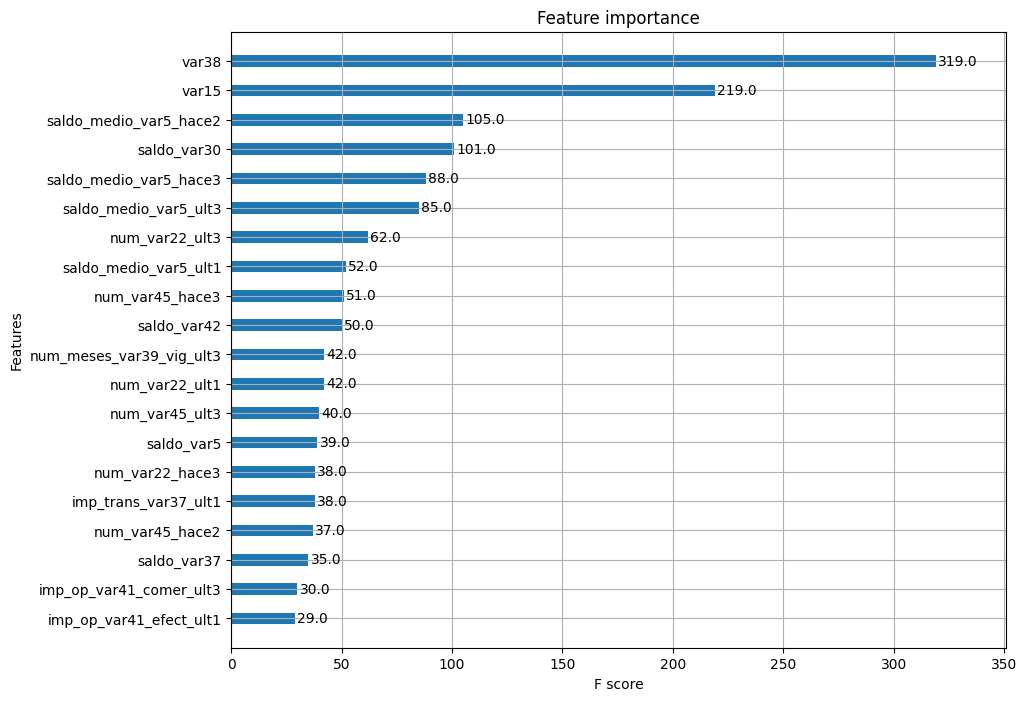

In [25]:
from xgboost import plot_importance
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize = (10, 8))
plot_importance(xgb_clf, ax= ax, max_num_features=20, height= 0.4)